# 01 · EDA of the synthetic sales data

Checks that the generator produces the realism the PRD asks for (section 5.1): weekly and yearly seasonality, a growth trend and noisy counts, then shows what the planted incidents look like next to normal seasonal dips.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
from kpi_detective.data.generator import generate_sales, daily_total
df = generate_sales(seed=0)
print(f"{len(df):,} rows, {df['date'].nunique()} days, {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
df.head()

434,016 rows, 1096 days, 2023-01-01 to 2025-12-31


,date,region,country,channel,product_category,customer_segment,sessions,orders,units,unit_price,revenue
0,2023-01-01,NA,US,Online,Laptops,Consumer,30225,686,753,1091.08,821583.24
1,2023-01-01,NA,US,Online,Monitors,Consumer,18835,473,529,320.73,169666.17
2,2023-01-01,NA,US,Online,Servers,Consumer,455,7,7,6620.34,46342.38
3,2023-01-01,NA,US,Online,Accessories,Consumer,36447,1094,1205,44.68,53839.40
4,2023-01-01,NA,US,Retail Partner,Laptops,Consumer,5172,427,468,1082.73,506717.64


## Revenue mix by dimension

In [2]:
shares = {d: (df.groupby(d)['revenue'].sum() / df['revenue'].sum()).sort_values(ascending=False)
          for d in ['region', 'channel', 'product_category', 'customer_segment']}
pd.concat(shares, names=['dimension', 'value']).to_frame('revenue share').style.format('{:.1%}')

## Daily revenue: trend, yearly events and weekly rhythm

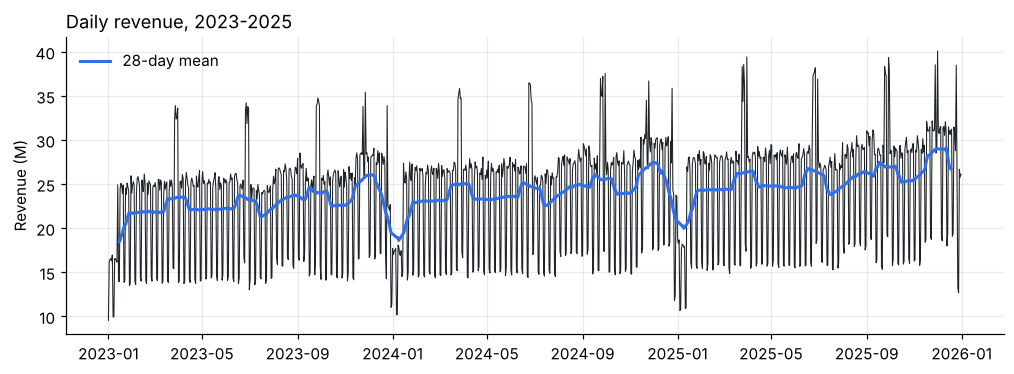

In [3]:
t = daily_total(df)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(t.index, t / 1e6, lw=0.7, color='#1f2328')
ax.plot(t.index, t.rolling(28, center=True).mean() / 1e6, lw=2, color='#2f6feb', label='28-day mean')
ax.set_ylabel('Revenue (M)'); ax.legend(frameon=False); ax.set_title('Daily revenue, 2023-2025', loc='left')
plt.show()

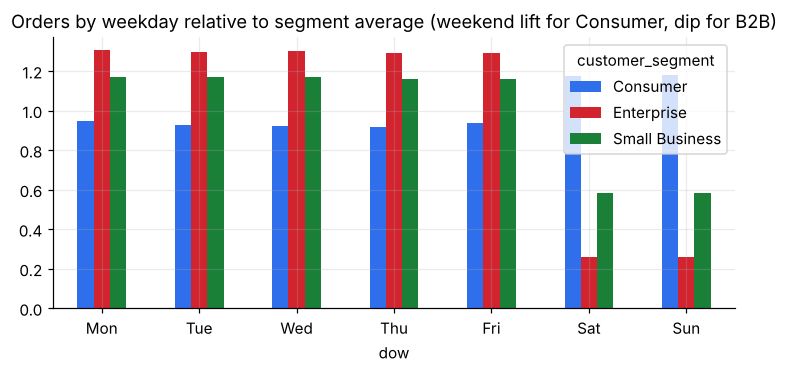

In [4]:
seg = df.assign(dow=df['date'].dt.day_name().str[:3]).groupby(['customer_segment', 'dow'])['orders'].sum().unstack(0)
seg = seg.loc[['Mon','Tue','Wed','Thu','Fri','Sat','Sun']]
(seg / seg.mean()).plot(kind='bar', figsize=(8, 3.2), color=['#2f6feb', '#d1242f', '#1a7f37'], rot=0,
                        title='Orders by weekday relative to segment average (weekend lift for Consumer, dip for B2B)')
plt.show()

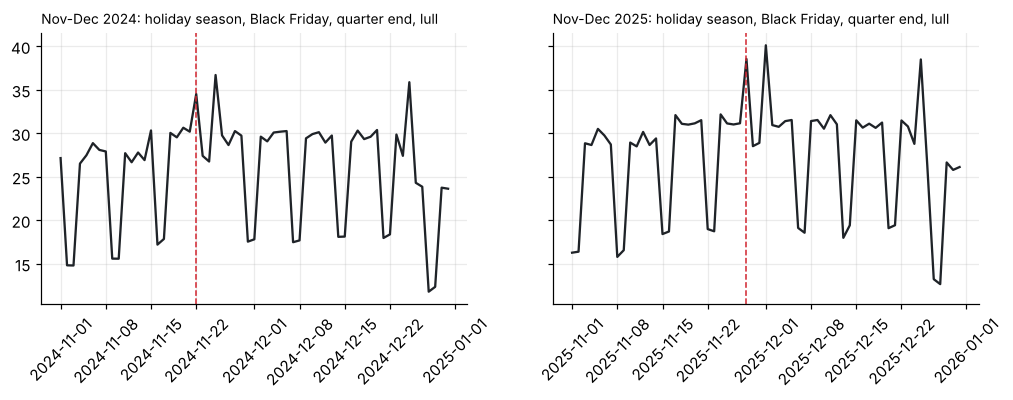

In [5]:
from kpi_detective.data.calendar import black_friday
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, year in zip(axes, [2024, 2025]):
    w = t[f'{year}-11-01':f'{year}-12-31'] if year == 2024 else t[f'{year}-11-01':f'{year}-12-31']
    ax.plot(w.index, w / 1e6, color='#1f2328')
    ax.axvline(pd.Timestamp(black_friday(year)), color='#d1242f', ls='--', lw=1)
    ax.set_title(f'Nov-Dec {year}: holiday season, Black Friday, quarter end, lull', loc='left', fontsize=9)
    ax.tick_params(axis='x', rotation=45)
plt.show()

## Noise level

The naive alert compares a window with the same weekday over the previous 4 weeks. In quiet periods its 3-day deviation has a standard deviation of roughly 1.3%, so incidents below about 2-3% of total revenue are genuinely hard to see.

In [6]:
def window_dev(t, start, n=3):
    w = [start + pd.Timedelta(days=i) for i in range(n)]
    cur = sum(t[d] for d in w)
    base = sum(np.mean([t[d - pd.Timedelta(days=7 * k)] for k in range(1, 5)]) for d in w)
    return cur / base - 1
quiet = list(pd.date_range('2025-02-12', '2025-03-18')) + list(pd.date_range('2025-05-10', '2025-06-18'))
devs = pd.Series([window_dev(t, s) for s in quiet])
print(f"3-day window deviation in quiet periods: mean {devs.mean():+.2%}, sd {devs.std():.2%}")

3-day window deviation in quiet periods: mean +0.05%, sd 1.27%


## Planted incidents vs a normal seasonal dip

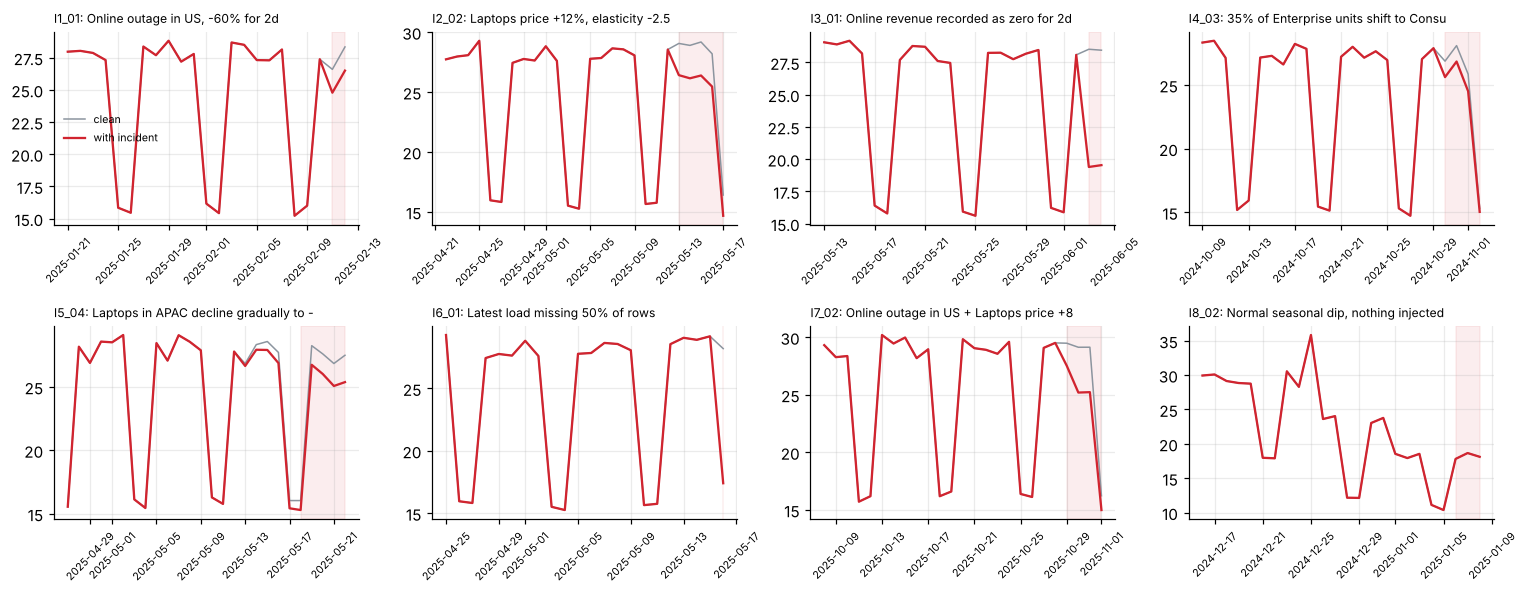

In [7]:
from kpi_detective.data.scenarios import load_scenarios, materialize
scns = {s.id: s for s in load_scenarios(ROOT / 'data/scenarios/dev')}
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, sid in zip(axes.ravel(), ['I1_01', 'I2_02', 'I3_01', 'I4_03', 'I5_04', 'I6_01', 'I7_02', 'I8_02']):
    s = scns[sid]
    clean = daily_total(generate_sales(seed=s.seed)); inc = daily_total(materialize(s))
    lo = pd.Timestamp(s.window_start) - pd.Timedelta(days=21)
    ax.plot(clean[lo:s.window_end].index, clean[lo:s.window_end] / 1e6, color='#8c959f', lw=1, label='clean')
    ax.plot(inc[lo:].index, inc[lo:] / 1e6, color='#d1242f', lw=1.5, label='with incident')
    ax.axvspan(pd.Timestamp(s.window_start), pd.Timestamp(s.window_end), color='#d1242f', alpha=0.08)
    ax.set_title(f"{sid}: {s.description[:38]}", fontsize=8, loc='left'); ax.tick_params(labelsize=7, axis='x', rotation=45)
axes[0, 0].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()

I8 (bottom right) is the trap: the naive alert fires because revenue is far below the previous four weeks, but the same dip happened last year. The forecast detector and `check_seasonality` both know this.